### Subagents
A deep agent can create subagents to delegate work. You can specify custom subagents in the subagents parameter. Subagents are useful for context quarantine (keeping the main agent’s context clean) and for providing specialized instructions.
This page covers synchronous subagents, where the supervisor blocks until the subagent finishes. For long-running tasks, parallel workstreams, or cases where you need mid-flight steering and cancellation, see Async subagents.

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

#os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

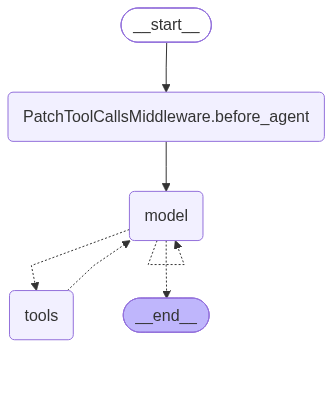

In [6]:
import os
from typing import Literal

from deepagents import create_deep_agent
from langchain_groq import ChatGroq
from tavily import TavilyClient

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,

):
 """Run a web search"""
 return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )


research_subagent={
    "name": "research-agent",
    "description": "Used to research more in depth questions",
    "system_prompt": "You are a great researcher",
    "tools": [internet_search],
    "model": "groq:openai/gpt-oss-20b",  # Optional override, defaults to main agent model

}
subagents=[research_subagent]

model = ChatGroq(
    model="openai/gpt-oss-120b"
)

agent=create_deep_agent(
    model=model,
    subagents=subagents
)
agent


In [7]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "Reserach about LLM Gateways and provide me a detailed summary.",       
          }],
          
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Reserach about LLM Gateways and provide me a detailed summary.
================================== Ai Message ==================================
Tool Calls:
  task (fc_224e3a6e-53e0-4ddb-b304-7aa15dd3d9b5)
 Call ID: fc_224e3a6e-53e0-4ddb-b304-7aa15dd3d9b5
  Args:
    description: Research the concept of LLM Gateways. Provide a comprehensive summary covering:
- Definition and purpose of LLM Gateways.
- Typical architecture and components (e.g., request routing, authentication, rate limiting, model orchestration, caching, monitoring, logging, transformation layers).
- Key examples or products in the market (e.g., OpenAI API gateway, Azure OpenAI, LangChain's LLM wrappers, LlamaIndex, Cohere, Anthropic, Hugging Face Inference Endpoints, custom gateway solutions like LangChain Hub, LLM Gateway frameworks like FastAPI wrappers, etc.).
- Benefits of using an LLM Gateway (security, cost control, multi-model orche

### structured Output With Sub Agents

In [8]:
from pydantic import BaseModel, Field
from deepagents import create_deep_agent

class ResearchFindings(BaseModel):
    """Structured findings from a research task."""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(description="Confidence score from 0 to 1")
    sources: list[str] = Field(description="List of source URLs")

research_subagent = {
    "name": "researcher",
    "description": "Researches topics and returns structured findings",
    "system_prompt": "Research the given topic thoroughly. Return your findings.",
    "tools": [internet_search],
    "response_format": ResearchFindings,
}

agent = create_deep_agent(
    model=model,
    subagents=[research_subagent],
)

result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "Research recent advances in quantum computing"}]}
)

In [9]:
# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Research recent advances in quantum computing
================================== Ai Message ==================================

Below is a concise, up‑to‑date overview of the most noteworthy advances in quantum computing (late 2022 – 2025).  I’ve grouped the progress into hardware platforms, error‑correction & fault‑tolerance, algorithms & applications, software & tooling, and industry/commercial milestones.  Where possible I note the primary papers, pre‑prints, or public announcements so you can dig deeper.

---

## 1. Hardware Platforms  

| Platform | Key Advances (2022‑2025) | Representative Papers / Announcements |
|----------|--------------------------|----------------------------------------|
| **Superconducting qubits** (IBM, Google, Rigetti, Alibaba) | • **Scale‑up to > 500‑qubit processors** – IBM’s *Eagle* (127 qubits, 2022) → *Condor* (1,121 qubits, announced 2024) with a modular “quantum‑fabr